# FloodNet Track 1 — DeepLabV3+ sobre la misma partición

Cuaderno de comparación. Entrena **DeepLabV3+ con encoder ResNet-50** (`segmentation-models-pytorch`)
con exactamente las mismas 317 / 40 / 41 imágenes de train / val / test que el U-Net híbrido de
`floodnet-segmentation.ipynb`. Lo evalúa con la misma métrica (mIoU por acumulación de matriz de
confusión) y deja el modelo exportado a **ONNX** para medir después la inferencia en el mismo equipo.

## Por qué DeepLabV3+

Es el *baseline* clásico de segmentación semántica y, a diferencia de YOLO-seg, encaja con el problema
sin adaptaciones:

- Predice **una clase por píxel**: usa las máscaras tal cual, sin convertirlas a instancias.
- El ONNX resultante es **un único tensor de logits** (1×10×512×512). Todo el cómputo está dentro del
  grafo y el post-proceso es solo un `argmax`, así que medir el rendimiento es directo.
- Arquitectura conocida: el módulo ASPP (convoluciones dilatadas a varias escalas) da contexto
  multiescala y el decoder ligero recupera bordes a 1/4 de resolución.

Se entrena deliberadamente **sin los añadidos del cuaderno principal** (oversampling con doble
augmentación, Focal + Lovász, *deep supervision*, TTA). Es una referencia limpia: si el U-Net híbrido
la supera, la diferencia se debe a su arquitectura y a su receta de entrenamiento.

## Índice

| Sección | Contenido |
|---|---|
| **P** | Parámetros del experimento (todo lo configurable, en un sitio) |
| **0** | Entorno |
| **1** | Datos y partición (idéntica al cuaderno principal) |
| **2** | Dataset, augmentación y pesos por clase |
| **3** | Modelo, pérdida y entrenamiento |
| **4** | Evaluación en test |
| **5** | Exportación a ONNX y verificación |

---
# P. Parámetros del experimento

**Todas las decisiones configurables están en esta celda.** Se imprimen aquí y se guardan, junto con
la lista de imágenes de cada partición y los resultados, en
`models/deeplabv3plus_r50_floodnet_config.json`, al lado del `.onnx`.

Sobre la resolución: **se entrena a 512×512**, la misma entrada que el U-Net híbrido y que
YOLO11n-seg. Se reutiliza la caché `data/cache512` y las tres comparaciones son de igual a igual.

In [1]:
import json
import os
import random
import time
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

CONFIG = {
    "experimento": "deeplabv3plus_r50_floodnet_512",
    # --- datos y partición (idénticos a floodnet-segmentation.ipynb) ---
    "img_size": 512,                    # entrada del modelo = tamaño de la caché
    "seed": 42,                         # split (train_test_split) y entrenamiento
    "split": {
        "train": "data_finally/train completo (317)",
        "val":   "50 % de data_finally/val, estratificado por categoría (40)",
        "test":  "el otro 50 % de data_finally/val (41)",
    },
    # --- modelo ---
    "arquitectura": "DeepLabV3Plus",
    "encoder": "resnet50",
    "encoder_weights": "imagenet",
    "encoder_output_stride": 16,
    # --- entrenamiento ---
    "epochs": 80,
    "batch": 8,
    "workers": 0,                       # Windows + Jupyter: el Dataset definido aquí no se puede usar con workers por spawn
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "scheduler": "CosineAnnealingLR(T_max=epochs)",
    "amp": True,
    "perdida": "CrossEntropy ponderada 1/log(1.02+n) + Dice multiclase",
    "peso_dice": 1.0,
    "ignore_index": 255,                # píxeles de relleno que introduce la augmentación geométrica
    "augmentacion": "aug_normal del cuaderno principal: flips, rot90, affine, brillo/contraste, gamma",
    "seleccion_checkpoint": "mejor mIoU (10 clases) en val",
    "tta": False,                       # una sola pasada, igual que el ONNX
    # --- exportación ---
    "onnx_opset": 18,                   # el nativo del exportador dynamo de torch 2.14
    "checkpoint": "models/deeplabv3plus_r50_best.pt",
    "onnx_path": "models/deeplabv3plus_r50_floodnet.onnx",
    "config_json": "models/deeplabv3plus_r50_floodnet_config.json",
}

# Poner ENTRENAR = False reutiliza el checkpoint de una ejecución anterior.
ENTRENAR = True

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
torch.cuda.manual_seed_all(CONFIG["seed"])

print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "experimento": "deeplabv3plus_r50_floodnet_512",
  "img_size": 512,
  "seed": 42,
  "split": {
    "train": "data_finally/train completo (317)",
    "val": "50 % de data_finally/val, estratificado por categoría (40)",
    "test": "el otro 50 % de data_finally/val (41)"
  },
  "arquitectura": "DeepLabV3Plus",
  "encoder": "resnet50",
  "encoder_weights": "imagenet",
  "encoder_output_stride": 16,
  "epochs": 80,
  "batch": 8,
  "workers": 0,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "scheduler": "CosineAnnealingLR(T_max=epochs)",
  "amp": true,
  "perdida": "CrossEntropy ponderada 1/log(1.02+n) + Dice multiclase",
  "peso_dice": 1.0,
  "ignore_index": 255,
  "augmentacion": "aug_normal del cuaderno principal: flips, rot90, affine, brillo/contraste, gamma",
  "seleccion_checkpoint": "mejor mIoU (10 clases) en val",
  "tta": false,
  "onnx_opset": 18,
  "checkpoint": "models/deeplabv3plus_r50_best.pt",
  "onnx_path": "models/deeplabv3plus_r50_floodnet.onnx",
  "config_json": "models

---
# 0. Entorno

Se usa el mismo entorno `uv` que el cuaderno principal. Si es la primera vez, desde la raíz del
proyecto:

```bash
uv sync
uv run python -m ipykernel install --user --name floodnet --display-name "FloodNet (Python 3.12)"
```

y selecciona el kernel **FloodNet (Python 3.12)**. `pyproject.toml` ya incluye `ultralytics`,
`segmentation-models-pytorch`, `onnx`, `onnxscript`, `onnxslim` y `onnxruntime-gpu`.

`onnxruntime-gpu` está fijado a la 1.24: las ruedas más recientes de PyPI están compiladas contra
CUDA 13 y no cargan junto a PyTorch cu126.

In [2]:
import sys
import torch

print("Python  :", sys.version.split()[0], "-", sys.executable)
print("PyTorch :", torch.__version__, "| CUDA build:", torch.version.cuda)
assert torch.cuda.is_available(), "Sin GPU: el entrenamiento sería inviable."
print("GPU     :", torch.cuda.get_device_name(0))

import segmentation_models_pytorch as smp
print("smp     :", smp.__version__)
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True

Python  : 3.12.10 - c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\.venv\Scripts\python.exe
PyTorch : 2.14.0+cu126 | CUDA build: 12.6
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU


smp     : 0.5.0


---
# 1. Datos y partición

Esta sección reproduce **exactamente** las secciones 1.1, 1.3 y 1.4 de
`floodnet-segmentation.ipynb`, para que el modelo se entrene y se evalúe sobre las mismas imágenes
que el U-Net híbrido:

| Partición | Origen | Imágenes |
|---|---|---:|
| train | `data_finally/train` | 317 |
| val | mitad de `data_finally/val`, estratificada por categoría (`SEED = 42`) | 40 |
| test | la otra mitad | 41 |

Si `data/cache512` ya existe (lo genera el cuaderno principal) se reutiliza; si no, se construye
aquí con el mismo código: imagen reducida con `INTER_AREA`, máscara con `INTER_NEAREST`.

### 1.1 Rutas y mapa de clases

In [3]:
PROJECT = Path.cwd()
DATA    = PROJECT / "data"
FIXED   = DATA / "data_finally"                      # 398 imgs, máscaras reparadas
OFICIAL = DATA / "FloodNet Challenge - Track 1"      # dataset original del reto
CACHE   = DATA / "cache512"                          # caché compartida con el cuaderno principal
MODELS  = PROJECT / "models"                         # .onnx, checkpoints y JSON de parámetros
MODELS.mkdir(exist_ok=True)

for p in (FIXED, OFICIAL):
    assert p.is_dir(), f"No encuentro {p}"

# class_mapping.csv trae dos tablas pegadas: columnas 0-1 son la tarea de
# clasificación (2 clases) y columnas 3-4 la de segmentación (10 clases).
_df = pd.read_csv(OFICIAL / "class_mapping.csv")
seg = _df.iloc[:, 3:5].copy()
seg.columns = ["Class Index", "Class Name"]
seg = seg.dropna(subset=["Class Index"])
seg = seg[seg["Class Index"].astype(str).str.isnumeric()]
class_mapping = seg.reset_index(drop=True)
class_mapping["Class Index"] = class_mapping["Class Index"].astype(int)

NUM_CLASSES = len(class_mapping)
class_names = class_mapping["Class Name"].tolist()
assert NUM_CLASSES == 10 and class_mapping["Class Index"].tolist() == list(range(10))

# Mapa stem -> categoría (Flooded / Non-Flooded), que data_finally no conserva.
categoria = {}
for cat in ("Flooded", "Non-Flooded"):
    for f in os.listdir(OFICIAL / "Train" / "Labeled" / cat / "image"):
        categoria[Path(f).stem] = cat

print(class_mapping.to_string(index=False))

 Class Index           Class Name
           0           Background
           1     Building-flooded
           2 Building-non-flooded
           3         Road-flooded
           4     Road-non-flooded
           5                Water
           6                 Tree
           7              Vehicle
           8                 Pool
           9                Grass


### 1.2 Caché a 512×512

In [4]:
SIZE = CONFIG["img_size"]
assert SIZE == 512, "La caché compartida está a 512; otro tamaño exigiría regenerarla."

def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    # cv2.imread falla con rutas no ASCII en Windows; esto no.
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, flags) if data.size else None

def construir_cache():
    filas = []
    for split_origen in ("train", "val"):
        img_dir = FIXED / split_origen / "image"
        msk_dir = FIXED / split_origen / "mask"
        out_img = CACHE / "image"
        out_msk = CACHE / "mask"
        out_img.mkdir(parents=True, exist_ok=True)
        out_msk.mkdir(parents=True, exist_ok=True)

        for f in tqdm(sorted(os.listdir(img_dir)), desc=f"Caché {split_origen}"):
            stem = Path(f).stem
            dst_i, dst_m = out_img / f"{stem}.png", out_msk / f"{stem}.png"

            if not (dst_i.exists() and dst_m.exists()):
                img = imread_unicode(img_dir / f, cv2.IMREAD_COLOR)
                msk = imread_unicode(msk_dir / f"{stem}.png", cv2.IMREAD_GRAYSCALE)
                if img is None or msk is None:
                    print("  aviso: no se pudo leer", stem)
                    continue
                if msk.shape[:2] != img.shape[:2]:
                    msk = cv2.resize(msk, (img.shape[1], img.shape[0]),
                                     interpolation=cv2.INTER_NEAREST)
                img = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
                msk = cv2.resize(msk, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
                cv2.imwrite(str(dst_i), img)
                cv2.imwrite(str(dst_m), msk)

            filas.append({"stem": stem,
                          "image": str(dst_i),
                          "mask": str(dst_m),
                          "origen": split_origen,
                          "category": categoria.get(stem, "?")})
    return pd.DataFrame(filas)

cache_csv = CACHE / "index.csv"
if cache_csv.exists():
    idx = pd.read_csv(cache_csv, dtype={"stem": str})
    print("Caché ya existente:", len(idx), "pares en", CACHE)
else:
    idx = construir_cache()
    idx.to_csv(cache_csv, index=False, encoding="utf-8")
    print("Caché construida:", len(idx), "pares en", CACHE)

# index.csv guarda rutas absolutas de la máquina que lo creó: se recomponen
# desde el stem para que el cuaderno funcione aunque el proyecto cambie de sitio.
idx["image"] = [str(CACHE / "image" / f"{s}.png") for s in idx["stem"]]
idx["mask"]  = [str(CACHE / "mask"  / f"{s}.png") for s in idx["stem"]]
assert all(Path(p).exists() for p in idx["image"]) and all(Path(p).exists() for p in idx["mask"])

print(idx.groupby(["origen", "category"]).size().to_string())

Caché ya existente: 398 pares en C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\cache512
origen  category   
train   Flooded         40
        Non-Flooded    277
val     Flooded         11
        Non-Flooded     70


### 1.3 Split definitivo (idéntico al del cuaderno principal)

In [5]:
SEED = CONFIG["seed"]

tr = idx[idx["origen"] == "train"]
ho = idx[idx["origen"] == "val"]        # holdout: nunca se entrena con estas

val_df, test_df = train_test_split(
    ho, test_size=0.5, random_state=SEED, shuffle=True, stratify=ho["category"]
)

train_imgs,  train_masks = tr["image"].tolist(),     tr["mask"].tolist()
val_imgs,    val_masks   = val_df["image"].tolist(), val_df["mask"].tolist()
test_imgs,   test_masks  = test_df["image"].tolist(), test_df["mask"].tolist()

split_stems = {
    "train": sorted(tr["stem"].tolist()),
    "val":   sorted(val_df["stem"].tolist()),
    "test":  sorted(test_df["stem"].tolist()),
}

print(f"Train : {len(train_imgs):>4}")
print(f"Val   : {len(val_imgs):>4}")
print(f"Test  : {len(test_imgs):>4}")

# Mismos tamaños que en floodnet-segmentation.ipynb y ninguna imagen repetida.
assert (len(train_imgs), len(val_imgs), len(test_imgs)) == (317, 40, 41), "El split no coincide"
s_tr, s_va, s_te = map(set, split_stems.values())
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "¡Fuga de datos!"
print("\nSin solapamiento entre train / val / test.")
print("Primeros stems de test:", split_stems["test"][:8], "...")

Train :  317
Val   :   40
Test  :   41

Sin solapamiento entre train / val / test.
Primeros stems de test: ['10819', '10840', '6426', '6477', '6585', '6692', '6727', '6750'] ...


### 1.4 Métricas

Es la misma `SegMetrics` del cuaderno principal (sección 5.5): acumula la matriz de confusión de
todo el conjunto y divide **una sola vez al final**. Si una clase no tiene píxeles ni en la
predicción ni en la referencia, su IoU es `NaN` y queda fuera de la media.

La única diferencia es que la matriz tiene una **columna extra para "sin predicción" (void)**. YOLO
puede dejar píxeles sin cubrir. Esos píxeles cuentan como fallo de su clase real, porque suman a
`reales` pero nunca a `tp`, y no se asignan a ninguna clase predicha. En un modelo que predice
todos los píxeles, como DeepLab, la columna queda a cero y el resultado es idéntico al de la versión
original.

In [6]:
class SegMetrics:
    # Matriz de confusión conf[real, predicho], con una columna extra para void.

    def __init__(self, num_classes=10):
        self.n = num_classes
        self.reset()

    def reset(self):
        self.conf = np.zeros((self.n, self.n + 1), dtype=np.int64)

    def update_labels(self, pred, target):
        # pred, target: mapas de etiquetas (H, W) o (B, H, W). pred == n significa void.
        n = self.n
        pred = np.asarray(pred).reshape(-1).astype(np.int64)
        target = np.asarray(target).reshape(-1).astype(np.int64)
        valido = (target >= 0) & (target < n)
        pred = np.where((pred >= 0) & (pred < n), pred, n)
        idx_ = target[valido] * (n + 1) + pred[valido]
        self.conf += np.bincount(idx_, minlength=n * (n + 1)).reshape(n, n + 1)

    def _sumas(self):
        tp = np.diag(self.conf[:, :self.n]).astype(np.float64)
        reales = self.conf.sum(axis=1).astype(np.float64)              # incluye lo que quedó en void
        predichos = self.conf[:, :self.n].sum(axis=0).astype(np.float64)
        return tp, predichos, reales

    def iou_per_class(self):
        tp, predichos, reales = self._sumas()
        union = predichos + reales - tp
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(union > 0, tp / union, np.nan)

    def dice_per_class(self):
        tp, predichos, reales = self._sumas()
        denom = predichos + reales
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(denom > 0, 2 * tp / denom, np.nan)

    def pixel_accuracy(self):
        total = self.conf.sum()
        return float(np.diag(self.conf[:, :self.n]).sum() / total) if total else float("nan")

    def void_fraction(self):
        total = self.conf.sum()
        return float(self.conf[:, self.n].sum() / total) if total else float("nan")

    def summary(self, ignore=()):
        # (mIoU, mDice, accuracy) sobre las clases presentes, excluyendo `ignore`.
        iou, dice = self.iou_per_class(), self.dice_per_class()
        keep = [c for c in range(self.n) if c not in ignore]
        with np.errstate(invalid="ignore"):
            return float(np.nanmean(iou[keep])), float(np.nanmean(dice[keep])), self.pixel_accuracy()


def informe(met, titulo):
    # Imprime el resumen con y sin Background y devuelve la tabla por clase.
    miou, mdice, acc = met.summary()
    miou_nb, mdice_nb, _ = met.summary(ignore=(0,))
    print(f"== {titulo} ==")
    print(f"  mIoU  : {miou:.4f}   (sin Background: {miou_nb:.4f})")
    print(f"  Dice  : {mdice:.4f}   (sin Background: {mdice_nb:.4f})")
    print(f"  PixAcc: {acc:.4f}")
    if met.void_fraction() > 0:
        print(f"  Píxeles sin predicción (void): {100 * met.void_fraction():.2f} %")
    tabla = pd.DataFrame({"Clase": class_names,
                          "Dice": met.dice_per_class(),
                          "IoU": met.iou_per_class()}).round(3)
    return {"mIoU": miou, "mIoU_sin_bg": miou_nb, "Dice": mdice, "Dice_sin_bg": mdice_nb,
            "PixAcc": acc, "void": met.void_fraction()}, tabla


# Paleta fija por clase (índice 10 = void, negro) para todas las figuras.
PALETA = np.array([
    [  0,   0,   0],   # 0 Background
    [255,   0,   0],   # 1 Building-flooded
    [180, 120, 120],   # 2 Building-non-flooded
    [160, 150,  20],   # 3 Road-flooded
    [140, 140, 140],   # 4 Road-non-flooded
    [ 61, 230, 250],   # 5 Water
    [  0,  82, 255],   # 6 Tree
    [255,   0, 245],   # 7 Vehicle
    [255, 235,   0],   # 8 Pool
    [  4, 250,   7],   # 9 Grass
    [ 30,  30,  30],   # 10 void
], dtype=np.uint8)

def colorear(lab):
    return PALETA[np.clip(lab, 0, len(PALETA) - 1)]

---
# 2. Dataset, augmentación y pesos por clase

La augmentación de entrenamiento es `aug_normal` del cuaderno principal (sección 3.1) con un único
cambio: los píxeles de relleno que crea `A.Affine` al rotar o desplazar se marcan en la máscara con
`ignore_index = 255`, en vez de con 0 (*Background*). Así la pérdida no aprende que los bordes negros
de relleno son una clase.

Las imágenes de la caché están en BGR (se escribieron con `cv2.imwrite`) y se pasan a **RGB**, que es
lo que espera el encoder preentrenado en ImageNet y lo que recibirá el ONNX.

In [7]:
IGN = CONFIG["ignore_index"]
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

aug_train = A.Compose([
    A.Resize(SIZE, SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.1, 0.1), rotate=(-30, 30),
             fill=0, fill_mask=IGN, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.RandomGamma(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

aug_eval = A.Compose([
    A.Resize(SIZE, SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

class FloodDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.image_paths[i]), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[i], cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].long()

g = torch.Generator().manual_seed(CONFIG["seed"])
train_loader = DataLoader(FloodDataset(train_imgs, train_masks, aug_train), batch_size=CONFIG["batch"],
                          shuffle=True, drop_last=True, num_workers=CONFIG["workers"], generator=g,
                          pin_memory=True)
val_loader  = DataLoader(FloodDataset(val_imgs, val_masks, aug_eval), batch_size=CONFIG["batch"],
                         num_workers=CONFIG["workers"])
test_loader = DataLoader(FloodDataset(test_imgs, test_masks, aug_eval), batch_size=CONFIG["batch"],
                         num_workers=CONFIG["workers"])

print(f"Lotes: train {len(train_loader)} · val {len(val_loader)} · test {len(test_loader)}")

Lotes: train 39 · val 5 · test 6


**Pesos por clase.** Misma fórmula que el cuaderno principal (sección 5.2): se cuenta en **cuántas
imágenes de train** aparece cada clase y se pondera con `1 / log(1.02 + n)`, normalizado para que
la media sea 1. Las clases raras pesan más sin llegar a pesos desorbitados.

In [8]:
conteo_imgs = np.zeros(NUM_CLASSES, dtype=np.int64)
for mp in train_masks:
    for c in np.unique(cv2.imread(mp, cv2.IMREAD_GRAYSCALE)):
        if 0 <= c < NUM_CLASSES:
            conteo_imgs[c] += 1

class_weights = 1 / np.log(1.02 + np.maximum(conteo_imgs, 1))
class_weights = class_weights / class_weights.sum() * NUM_CLASSES

pd.DataFrame({"Clase": class_names, "Imágenes train": conteo_imgs,
              "Peso": class_weights.round(3)})

,Clase,Imágenes train,Peso
0,Background,20,1.413
1,Building-flooded,29,1.265
2,Building-non-flooded,115,0.905
3,Road-flooded,29,1.265
4,Road-non-flooded,169,0.838
5,Water,180,0.828
6,Tree,246,0.781
7,Vehicle,102,0.929
8,Pool,65,1.027
9,Grass,317,0.747


---
# 3. Modelo, pérdida y entrenamiento

- **Modelo**: `smp.DeepLabV3Plus` con encoder ResNet-50 preentrenado en ImageNet y *output stride*
  16. La salida tiene ya la resolución de la entrada: logits 10×512×512.
- **Pérdida**: entropía cruzada ponderada + Dice multiclase. La CE optimiza la clasificación píxel a
  píxel; el Dice compensa el desbalance de área (Grass ocupa ~60 % de la imagen y Vehicle ~0.5 %).
  Las dos ignoran los píxeles de relleno (255).
- **Optimización**: AdamW, coseno sobre las épocas y precisión mixta (AMP). Antes del recorte de
  gradiente se hace `scaler.unscale_()`, porque si no se recortan gradientes todavía escalados.
- **Selección**: se guarda el checkpoint con **mejor mIoU en val**, la métrica que se reporta. La
  pérdida de val no se usa para elegir.

La semilla fija el split, la inicialización del decoder y el orden de los lotes.
`cudnn.benchmark = True` acelera, pero hace que dos ejecuciones no sean idénticas bit a bit.

In [9]:
model = smp.DeepLabV3Plus(
    encoder_name=CONFIG["encoder"],
    encoder_weights=CONFIG["encoder_weights"],
    encoder_output_stride=CONFIG["encoder_output_stride"],
    classes=NUM_CLASSES,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros: {n_params / 1e6:.1f} M")

ce = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                         ignore_index=IGN)
dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=IGN)

def criterio(logits, target):
    return ce(logits, target) + CONFIG["peso_dice"] * dice(logits, target)

optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"])
scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["amp"])

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Parámetros: 26.7 M


In [10]:
def entrenar_epoca():
    model.train()
    total, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=CONFIG["amp"]):
            loss = criterio(model(x), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n

@torch.no_grad()
def evaluar(loader, amp=CONFIG["amp"]):
    # Devuelve (pérdida media, SegMetrics) sobre un loader sin augmentación.
    model.eval()
    met = SegMetrics(NUM_CLASSES)
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.amp.autocast("cuda", enabled=amp):
            logits = model(x)
        total += criterio(logits.float(), y).item() * x.size(0); n += x.size(0)
        met.update_labels(logits.argmax(1).cpu().numpy(), y.cpu().numpy())
    return total / n, met

In [11]:
CKPT = PROJECT / CONFIG["checkpoint"]

if ENTRENAR:
    hist, mejor = [], -1.0
    t0 = time.time()
    for ep in range(1, CONFIG["epochs"] + 1):
        tl = entrenar_epoca()
        vl, met = evaluar(val_loader)
        miou, mdice, acc = met.summary()
        scheduler.step()
        hist.append({"epoch": ep, "train_loss": tl, "val_loss": vl, "val_mIoU": miou,
                     "val_mIoU_sin_bg": met.summary(ignore=(0,))[0], "val_Dice": mdice,
                     "val_PixAcc": acc, "lr": optimizer.param_groups[0]["lr"]})
        marca = ""
        if miou > mejor:
            mejor = miou
            torch.save(model.state_dict(), CKPT)
            marca = "  <- mejor"
        print(f"[{ep:3d}/{CONFIG['epochs']}] train {tl:.4f} · val {vl:.4f} · "
              f"mIoU {miou:.4f} · Dice {mdice:.4f} · acc {acc:.4f}{marca}")
    hist = pd.DataFrame(hist)
    hist.to_csv(CKPT.with_suffix(".csv"), index=False)
    print(f"\nEntrenamiento: {(time.time() - t0) / 60:.1f} min · mejor mIoU val {mejor:.4f}")
else:
    hist = pd.read_csv(CKPT.with_suffix(".csv"))

assert CKPT.exists(), f"No existe {CKPT}: entrena con ENTRENAR = True"

[  1/80] train 2.0350 · val 2.0077 · mIoU 0.3676 · Dice 0.4712 · acc 0.7915  <- mejor


[  2/80] train 1.2974 · val 1.1442 · mIoU 0.4122 · Dice 0.5108 · acc 0.8380  <- mejor


[  3/80] train 1.0045 · val 0.9640 · mIoU 0.4468 · Dice 0.5397 · acc 0.8631  <- mejor


[  4/80] train 0.8816 · val 0.8082 · mIoU 0.4994 · Dice 0.5804 · acc 0.8872  <- mejor


[  5/80] train 0.7913 · val 0.7743 · mIoU 0.4971 · Dice 0.5783 · acc 0.8849


...

[ 76/80] train 0.2309 · val 0.4878 · mIoU 0.6959 · Dice 0.7808 · acc 0.9235


[ 77/80] train 0.2284 · val 0.4791 · mIoU 0.6974 · Dice 0.7818 · acc 0.9244


[ 78/80] train 0.2354 · val 0.4845 · mIoU 0.6962 · Dice 0.7810 · acc 0.9242


[ 79/80] train 0.2265 · val 0.4836 · mIoU 0.6968 · Dice 0.7815 · acc 0.9244


[ 80/80] train 0.2401 · val 0.4776 · mIoU 0.6971 · Dice 0.7816 · acc 0.9245

Entrenamiento: 18.9 min · mejor mIoU val 0.6994


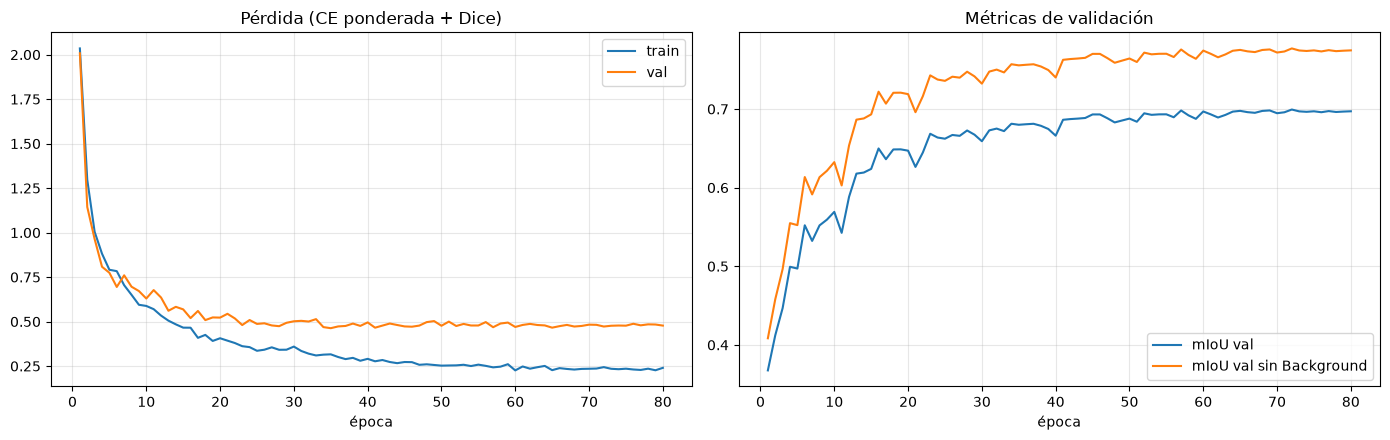

,epoch,train_loss,val_loss,val_mIoU,val_mIoU_sin_bg,val_Dice,val_PixAcc,lr
mejor época,72.0,0.2441,0.4723,0.6994,0.7771,0.783,0.9263,0.0


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train")
ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("Pérdida (CE ponderada + Dice)")
ax[1].plot(hist["epoch"], hist["val_mIoU"], label="mIoU val")
ax[1].plot(hist["epoch"], hist["val_mIoU_sin_bg"], label="mIoU val sin Background")
ax[1].set_title("Métricas de validación")
for a in ax:
    a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
hist.loc[hist["val_mIoU"].idxmax()].to_frame("mejor época").T.round(4)

---
# 4. Evaluación en test

Se recarga el mejor checkpoint y se evalúa una sola vez sobre las 41 imágenes de test, **en FP32 y sin
TTA**: una pasada por imagen, que es exactamente lo que hará el ONNX.

In [13]:
model.load_state_dict(torch.load(CKPT, map_location=device))
_, met_test = evaluar(test_loader, amp=False)
res_test, tabla_test = informe(met_test, "TEST (41 imágenes) — DeepLabV3+ R50")
tabla_test

== TEST (41 imágenes) — DeepLabV3+ R50 ==
  mIoU  : 0.6958   (sin Background: 0.7563)
  Dice  : 0.7961   (sin Background: 0.8552)
  PixAcc: 0.9218


,Clase,Dice,IoU
0,Background,0.264,0.152
1,Building-flooded,0.909,0.832
2,Building-non-flooded,0.887,0.797
3,Road-flooded,0.820,0.695
4,Road-non-flooded,0.867,0.765
5,Water,0.954,0.912
6,Tree,0.872,0.773
7,Vehicle,0.662,0.495
8,Pool,0.780,0.640
9,Grass,0.945,0.897


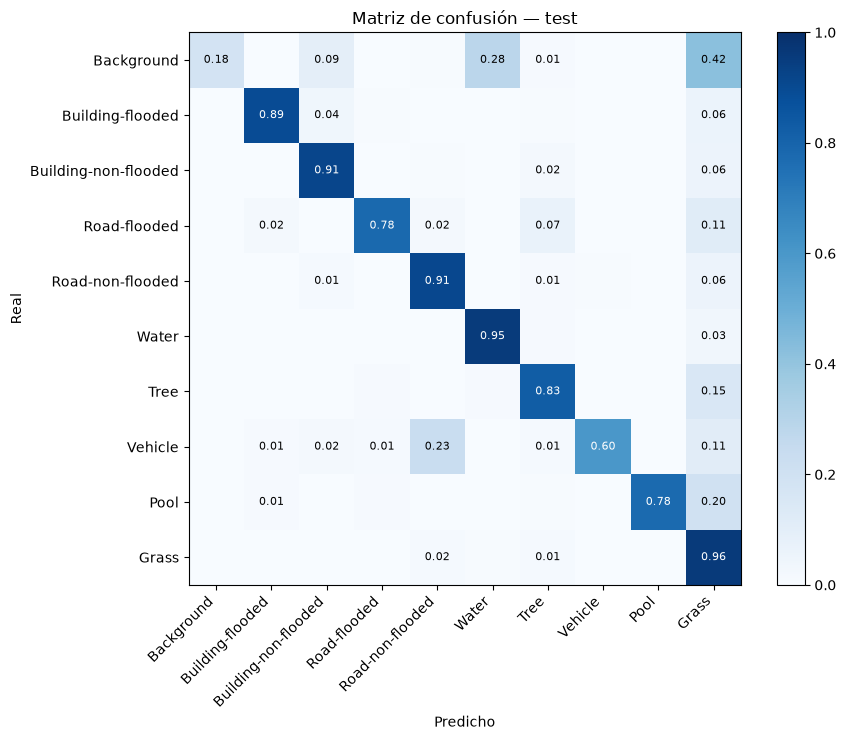

In [14]:
# Matriz de confusión normalizada por fila: qué fracción de cada clase real acaba en cada predicción.
conf = met_test.conf[:, :NUM_CLASSES].astype(np.float64)
conf_n = conf / np.maximum(conf.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(conf_n, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if conf_n[i, j] >= 0.01:
            ax.text(j, i, f"{conf_n[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if conf_n[i, j] > 0.5 else "black")
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión — test")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

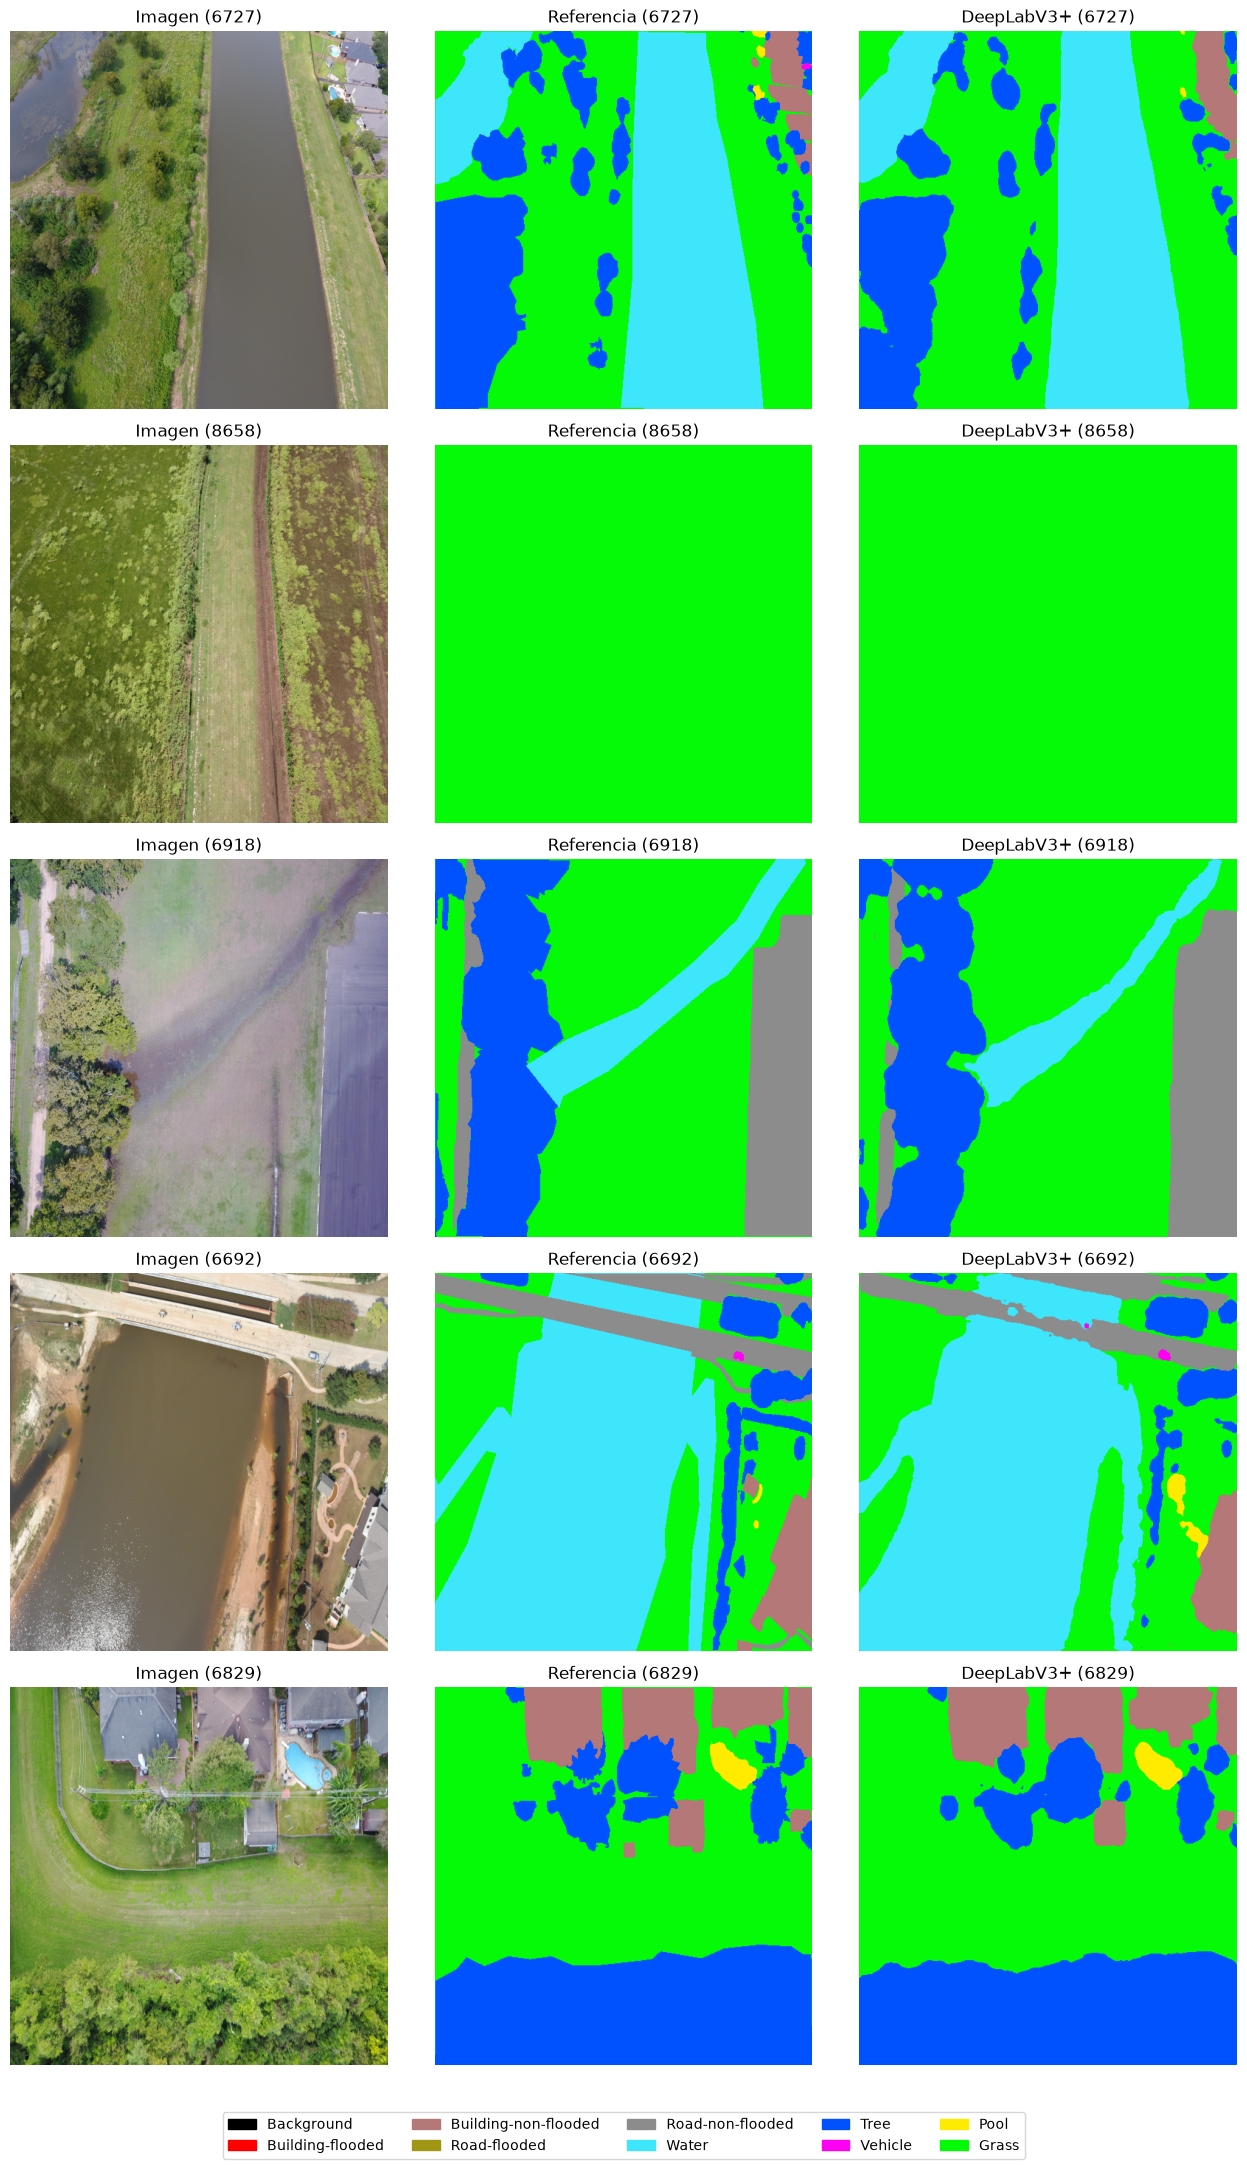

In [15]:
# Ejemplos de test: imagen, referencia y predicción.
@torch.no_grad()
def predecir(ruta):
    img = cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
    x = aug_eval(image=img)["image"].unsqueeze(0).to(device)
    return img, model(x).argmax(1)[0].cpu().numpy()

muestras = list(range(5))
fig, ax = plt.subplots(len(muestras), 3, figsize=(13, 4.3 * len(muestras)))
for fila, i in enumerate(muestras):
    img, pred = predecir(test_imgs[i])
    gt = cv2.imread(test_masks[i], cv2.IMREAD_GRAYSCALE)
    stem = Path(test_imgs[i]).stem
    for a, im, t in zip(ax[fila], [img, colorear(gt), colorear(pred)], ["Imagen", "Referencia", "DeepLabV3+"]):
        a.imshow(im); a.set_title(f"{t} ({stem})"); a.axis("off")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PALETA[c] / 255, label=n) for c, n in enumerate(class_names)],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

---
# 5. Exportación a ONNX y verificación

Se exporta un *wrapper* que incluye la **normalización de ImageNet dentro del grafo**. Así el ONNX
recibe la misma entrada que el de YOLO11n-seg y los dos se alimentan con el mismo tensor en el
benchmark:

| | |
|---|---|
| Entrada `images` | `float32` 1×3×512×512, **RGB** en [0, 1] (NCHW) |
| Salida `logits` | `float32` 1×10×512×512 |
| Post-proceso | `argmax` sobre el eje de clases. No hay NMS ni nada más fuera del grafo. |

Se usa el exportador por defecto de PyTorch 2.14 (`dynamo=True`, basado en `torch.export`) con opset
18. Los pesos van dentro del propio `.onnx` (`external_data=False`), en un único fichero.

La verificación ejecuta el ONNX con **ONNX Runtime** sobre las 41 imágenes de test y lo compara con
PyTorch en FP32: diferencia máxima de logits, % de píxeles con el mismo `argmax` y mIoU.

Los logits no coinciden bit a bit: PyTorch usa TF32 en las convoluciones de la GPU por defecto y
ONNX Runtime elige sus propios algoritmos de cuDNN. Lo relevante es que el `argmax` y el mIoU coincidan.


In [16]:
import onnx
import onnxruntime as ort

class ConNormalizacion(nn.Module):
    # Entrada RGB en [0,1]; aplica la normalización de ImageNet y llama al modelo.
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(STD).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)

ONNX_PATH = PROJECT / CONFIG["onnx_path"]
exportable = ConNormalizacion(model).eval().cpu()
dummy = torch.rand(1, 3, SIZE, SIZE)
torch.onnx.export(exportable, (dummy,), str(ONNX_PATH), input_names=["images"], output_names=["logits"],
                  opset_version=CONFIG["onnx_opset"], dynamo=True, external_data=False)

grafo = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(grafo)
def _forma(v):
    return [d.dim_value or d.dim_param for d in v.type.tensor_type.shape.dim]
io_onnx = {"inputs":  {v.name: _forma(v) for v in grafo.graph.input},
           "outputs": {v.name: _forma(v) for v in grafo.graph.output}}
print(ONNX_PATH, f"({ONNX_PATH.stat().st_size / 2**20:.1f} MB)")
print(json.dumps(io_onnx, indent=2))
_ = model.to(device)

W1013 21:29:40.210000 26784 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\models\deeplabv3plus_r50_floodnet.onnx (102.1 MB)
{
  "inputs": {
    "images": [
      1,
      3,
      512,
      512
    ]
  },
  "outputs": {
    "logits": [
      1,
      10,
      512,
      512
    ]
  }
}


In [17]:
sess = ort.InferenceSession(str(ONNX_PATH), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("Proveedor activo:", sess.get_providers()[0])

met_onnx = SegMetrics(NUM_CLASSES)
dif_max, coinciden, total = 0.0, 0, 0
exportable.to(device).eval()
for ip, mp in tqdm(list(zip(test_imgs, test_masks)), desc="test ONNX"):
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    x = (img.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]          # el contrato del ONNX
    y_onnx = sess.run(["logits"], {"images": x})[0]
    with torch.no_grad():
        y_pt = exportable(torch.from_numpy(x).to(device)).cpu().numpy()
    dif_max = max(dif_max, float(np.abs(y_onnx - y_pt).max()))
    p_onnx, p_pt = y_onnx.argmax(1)[0], y_pt.argmax(1)[0]
    coinciden += int((p_onnx == p_pt).sum()); total += p_onnx.size
    met_onnx.update_labels(p_onnx, cv2.imread(mp, cv2.IMREAD_GRAYSCALE))

res_onnx, _ = informe(met_onnx, "TEST — ONNX Runtime")
print(f"\nDiferencia máxima de logits ONNX vs PyTorch : {dif_max:.2e}")
print(f"Píxeles con el mismo argmax                : {100 * coinciden / total:.4f} %")
dif = abs(res_onnx["mIoU"] - res_test["mIoU"])
print(f"|mIoU ONNX - mIoU PyTorch|                 : {dif:.5f}")
assert dif < 0.005, "El ONNX no reproduce al modelo de PyTorch"

Proveedor activo:

 CUDAExecutionProvider


test ONNX:   0%|          | 0/41 [00:00<?, ?it/s]

== TEST — ONNX Runtime ==
  mIoU  : 0.6958   (sin Background: 0.7563)
  Dice  : 0.7961   (sin Background: 0.8552)
  PixAcc: 0.9218

Diferencia máxima de logits ONNX vs PyTorch : 4.11e-02
Píxeles con el mismo argmax                : 99.9928 %
|mIoU ONNX - mIoU PyTorch|                 : 0.00001


### 5.1 Registro de parámetros y resultados

Todo lo necesario para reproducir y evaluar el modelo sale en un único JSON: configuración, lista
exacta de imágenes de cada partición, contrato de entrada/salida del ONNX y cifras obtenidas.

In [18]:
mejor_ep = hist.loc[hist["val_mIoU"].idxmax()]
registro = {
    "config": CONFIG,
    "clases": class_names,
    "split_stems": split_stems,
    "parametros_modelo": int(n_params),
    "pesos_clase": dict(zip(class_names, class_weights.round(4).tolist())),
    "onnx": {
        "path": CONFIG["onnx_path"],
        **io_onnx,
        "preprocesado": "RGB, float32 en [0,1], NCHW 1x3x512x512; la normalización ImageNet va dentro del grafo",
        "postprocesado_fuera_del_grafo": ["argmax sobre el eje de clases"],
    },
    "resultados": {
        "mejor_epoca": int(mejor_ep["epoch"]),
        "val_en_mejor_epoca": {k: float(mejor_ep[k]) for k in ("val_mIoU", "val_mIoU_sin_bg", "val_Dice", "val_PixAcc")},
        "test_pytorch": res_test,
        "test_onnx": res_onnx,
        "test_por_clase": tabla_test.to_dict(orient="records"),
        "onnx_vs_pytorch": {"dif_max_logits": dif_max, "argmax_coincidente": coinciden / total},
    },
    "versiones": {"smp": smp.__version__, "torch": torch.__version__, "onnx": onnx.__version__,
                  "onnxruntime": ort.__version__, "albumentations": A.__version__},
}
(PROJECT / CONFIG["config_json"]).write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=float),
                                              encoding="utf-8")
print("Guardado:", CONFIG["config_json"])

Guardado: models/deeplabv3plus_r50_floodnet_config.json


---
# Conclusiones

Cifras de esta ejecución. Están también en `models/deeplabv3plus_r50_floodnet_config.json`.

| | DeepLabV3+ R50 | YOLO11n-seg | U-Net híbrido (README) |
|---|---:|---:|---:|
| mIoU test (10 clases) | **0.696** | 0.678 | 0.714 |
| mIoU test (sin *Background*) | **0.756** | 0.738 | 0.777 |
| Dice test (10 clases) | 0.796 | 0.783 | 0.809 |
| Pixel accuracy | 0.922 | 0.891 | 0.927 |
| TTA | no | no | sí (4 volteos) |
| Parámetros | 26.7 M | 2.9 M | — |

| Clase | IoU DeepLabV3+ | IoU YOLO11n-seg | IoU U-Net |
|---|---:|---:|---:|
| Water | 0.912 | 0.892 | 0.915 |
| Grass | 0.897 | 0.887 | 0.905 |
| Building-flooded | 0.832 | 0.851 | 0.831 |
| Building-non-flooded | 0.797 | 0.797 | 0.803 |
| Tree | 0.773 | 0.770 | 0.790 |
| Road-non-flooded | 0.765 | 0.684 | 0.777 |
| Road-flooded | 0.695 | 0.574 | 0.679 |
| Pool | 0.640 | 0.693 | 0.719 |
| Vehicle | 0.495 | 0.494 | 0.573 |
| Background | 0.152 | 0.142 | 0.144 |

Lecturas:

- **El baseline limpio queda a ~2 puntos de mIoU del U-Net híbrido**, sin oversampling, sin Focal +
  Lovász, sin *deep supervision* y sin TTA. Con 41 imágenes de test esa diferencia está en el
  margen de ruido que avisa el README. La receta del U-Net parece aportar sobre todo en *Vehicle* y
  *Pool*, las clases pequeñas.
- **Frente a YOLO11n-seg**, DeepLab gana justo donde YOLO sufre: en las carreteras
  (+8 / +12 puntos de IoU), que son regiones largas y fragmentadas, el peor caso para modelarlas como
  instancias. YOLO gana en *Building-flooded* y *Pool*, que se parecen más a objetos.
- **Para el benchmark de rendimiento**, el ONNX de DeepLab contiene todo el cómputo: el post-proceso
  es un `argmax`. El de YOLO deja fuera NMS, ensamblado de máscaras y repintado.
- La pérdida de val oscila en torno a 0.47–0.50 desde la época 25, y el mIoU de val se estanca en
  ~0.70 a partir de la 57. Con esta receta, más épocas no parecen prometer mucho.
